In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import RandomOverSampler

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from pathlib import Path

current_path = Path.cwd()

possible_roots = [current_path, *current_path.parents]

PROJECT_ROOT = next(
    (
        path for path in possible_roots
        if (
            path / "data" / "gerrit" /
            "couchbase_java_client" / "features"
        ).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Make sure the notebook is inside the project folder."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "gerrit"
    / "couchbase_java_client"
    / "features"
    / "gerrit_structured_features.csv"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

df = pd.read_csv(DATA_PATH)

print("\nDataset shape:", df.shape)

display(df.head())

Project root: /Users/mustafaahmed/Documents/Security Code Review Analysis
Dataset path: /Users/mustafaahmed/Documents/Security Code Review Analysis/data/gerrit/couchbase_java_client/features/gerrit_structured_features.csv
Dataset exists: True

Dataset shape: (2635, 34)


,review_number,revision_number,commit_id,security_label,diff_available,diff_character_count,diff_line_count,added_line_count,deleted_line_count,changed_file_count_from_diff,...,security_authorization_count,security_credentials_count,security_cryptography_count,security_input_validation_count,security_injection_count,added_security_indicator_count,deleted_security_indicator_count,git_fetch_success,comparison_success,status
0,12027,1,634fb3ea0b12e60b8d8b27d9aa3f36d5f394d83e,1,1.0,1528.0,40.0,8.0,2.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,True,ABANDONED
1,12050,1,dd6454bd6574a9337528281df912f51a9fda52ad,1,1.0,375403.0,8732.0,8348.0,12.0,51.0,...,102.0,29.0,0.0,0.0,0.0,134.0,0.0,True,True,MERGED
2,12050,2,8c338944a8c4e5e068db7009c41be5cbcb8b72f1,1,1.0,368273.0,8581.0,0.0,8281.0,50.0,...,102.0,31.0,0.0,0.0,0.0,0.0,136.0,True,True,MERGED
3,12050,3,eddbfeac3b56721994ab0bdc7a63ded3aec6bb1a,1,1.0,1297.0,30.0,3.0,5.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,True,MERGED
4,12050,4,ced15bea74bce3e242865edd18d5cb1370d2eecb,1,1.0,21565.0,504.0,75.0,74.0,20.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True,True,MERGED


Original security label distribution:


security_label
0      85
1    2550
Name: count, dtype: int64

security_label
0     3.23
1    96.77
Name: proportion, dtype: float64

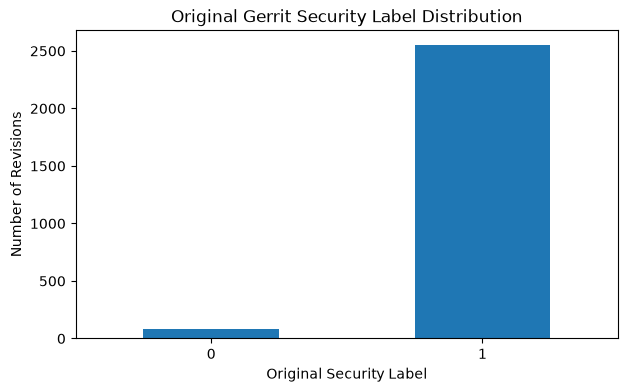

In [3]:
print("Original security label distribution:")
display(df["security_label"].value_counts().sort_index())

label_percentages = (
    df["security_label"].value_counts(normalize=True).sort_index() * 100
)

display(label_percentages.round(2))

df["security_label"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Original Gerrit Security Label Distribution")
plt.xlabel("Original Security Label")
plt.ylabel("Number of Revisions")
plt.xticks(rotation=0)
plt.show()

In [4]:
DIFF_PATH = (
    PROJECT_ROOT
    / "data"
    / "gerrit"
    / "couchbase_java_client"
    / "processed"
    / "finalized_gerrit.csv"
)

diff_df = pd.read_csv(
    DIFF_PATH,
    usecols=[
        "review_number",
        "revision_number",
        "code_diff"
    ]
)

model_df = df.merge(
    diff_df,
    on=["review_number", "revision_number"],
    how="left",
    validate="one_to_one"
)

model_df["code_diff"] = model_df["code_diff"].fillna("")

# Keep only revisions with actual code diffs.
model_df = model_df[
    (model_df["diff_available"] == 1) &
    (model_df["code_diff"].str.strip() != "")
].copy()

# Recode the target so security-related is the positive class.
model_df["target"] = (
    model_df["security_label"] == 0
).astype(int)

print("Modelling dataset:", model_df.shape)

print("\nTarget distribution:")
display(model_df["target"].value_counts().sort_index())

print("\nExpected: 71 security-related and 1,703 not security-related.")

Modelling dataset: (1774, 36)

Target distribution:


target
0    1703
1      71
Name: count, dtype: int64


Expected: 71 security-related and 1,703 not security-related.


In [5]:
class_counts = model_df["target"].value_counts().sort_index()

negative_count = class_counts[0]
positive_count = class_counts[1]

print("Not security-related:", negative_count)
print("Security-related:", positive_count)

print(
    "Majority-to-minority ratio:",
    round(negative_count / positive_count, 2),
    ": 1"
)

print(
    "Minority class percentage:",
    round((positive_count / len(model_df)) * 100, 2),
    "%"
)

Not security-related: 1703
Security-related: 71
Majority-to-minority ratio: 23.99 : 1
Minority class percentage: 4.0 %


In [6]:
X_rows = model_df.reset_index(drop=True)

y = X_rows["target"].values
groups = X_rows["review_number"].values

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

splits = []

for fold, (train_idx, test_idx) in enumerate(
    splitter.split(X_rows, y, groups)
):
    if (
        len(np.unique(y[train_idx])) == 2
        and len(np.unique(y[test_idx])) == 2
    ):
        splits.append((fold, train_idx, test_idx))

if not splits:
    raise ValueError(
        "No valid review-group split contains both classes. "
        "Do not use a random row split as a workaround."
    )

fold, train_idx, test_idx = splits[0]

train_df = X_rows.iloc[train_idx].copy()
test_df = X_rows.iloc[test_idx].copy()

y_train = y[train_idx]
y_test = y[test_idx]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("Training security-related:", sum(y_train))
print("Testing security-related:", sum(y_test))

print(
    "Overlapping reviews:",
    len(
        set(train_df["review_number"]) &
        set(test_df["review_number"])
    )
)

Training rows: 1419
Testing rows: 355
Training security-related: 57
Testing security-related: 14
Overlapping reviews: 0


In [7]:
excluded_columns = [
    "review_number",
    "revision_number",
    "commit_id",
    "security_label",
    "target",
    "code_diff",
    "diff_available",
    "status"
]

structured_columns = [
    col for col in train_df.select_dtypes(
        include=["number", "bool"]
    ).columns
    if col not in excluded_columns
]

# Remove features with no variation in the training data.
structured_columns = [
    col for col in structured_columns
    if train_df[col].nunique() > 1
]

print("Number of structured features:", len(structured_columns))
print(structured_columns)

Number of structured features: 25
['diff_character_count', 'diff_line_count', 'added_line_count', 'deleted_line_count', 'changed_file_count_from_diff', 'java_file_count', 'test_file_count', 'unique_file_extension_count', 'java_file_indicator', 'conditional_count', 'loop_count', 'exception_count', 'method_declaration_count', 'review_message_count', 'review_message_character_count', 'changed_files', 'insertions', 'deletions', 'security_authentication_count', 'security_authorization_count', 'security_credentials_count', 'security_cryptography_count', 'security_input_validation_count', 'added_security_indicator_count', 'deleted_security_indicator_count']


In [8]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_struct_train = imputer.fit_transform(
    train_df[structured_columns]
)

X_struct_test = imputer.transform(
    test_df[structured_columns]
)

X_struct_train = csr_matrix(
    scaler.fit_transform(X_struct_train)
)

X_struct_test = csr_matrix(
    scaler.transform(X_struct_test)
)

print("Structured training shape:", X_struct_train.shape)
print("Structured testing shape:", X_struct_test.shape)

Structured training shape: (1419, 25)
Structured testing shape: (355, 25)


In [9]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

X_tfidf_train = tfidf.fit_transform(
    train_df["code_diff"]
)

X_tfidf_test = tfidf.transform(
    test_df["code_diff"]
)

print("TF-IDF vocabulary:", len(tfidf.vocabulary_))
print("Training shape:", X_tfidf_train.shape)
print("Testing shape:", X_tfidf_test.shape)

TF-IDF vocabulary: 5000
Training shape: (1419, 5000)
Testing shape: (355, 5000)


In [10]:
X_combined_train = hstack(
    [X_struct_train, X_tfidf_train],
    format="csr"
)

X_combined_test = hstack(
    [X_struct_test, X_tfidf_test],
    format="csr"
)

print("Combined training shape:", X_combined_train.shape)
print("Combined testing shape:", X_combined_test.shape)

Combined training shape: (1419, 5025)
Combined testing shape: (355, 5025)


In [11]:
def evaluate_model(y_true, predictions, probabilities):
    return {
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "PR_AUC": average_precision_score(
            y_true, probabilities
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, predictions
        )
    }

In [12]:
feature_sets = {
    "Structured": (X_struct_train, X_struct_test),
    "TF-IDF": (X_tfidf_train, X_tfidf_test),
    "Combined": (X_combined_train, X_combined_test)
}

results = []
trained_models = {}

for feature_name, (Xtr, Xte) in feature_sets.items():

    for strategy in [
        "No balancing",
        "Class weighting",
        "Random oversampling"
    ]:

        if strategy == "No balancing":

            X_fit = Xtr
            y_fit = y_train

            model = LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            )

        elif strategy == "Class weighting":

            X_fit = Xtr
            y_fit = y_train

            model = LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )

        else:

            sampler = RandomOverSampler(
                random_state=RANDOM_STATE
            )

            X_fit, y_fit = sampler.fit_resample(
                Xtr,
                y_train
            )

            model = LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            )

        model.fit(X_fit, y_fit)

        predictions = model.predict(Xte)
        probabilities = model.predict_proba(Xte)[:, 1]

        metrics = evaluate_model(
            y_test,
            predictions,
            probabilities
        )

        results.append({
            "Feature Set": feature_name,
            "Imbalance Strategy": strategy,
            "Training Rows": X_fit.shape[0],
            **metrics
        })

        trained_models[(feature_name, strategy)] = model

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR_AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Feature Set,Imbalance Strategy,Training Rows,Precision,Recall,F1,PR_AUC,Balanced Accuracy
0,TF-IDF,Random oversampling,2724,0.2105,0.2857,0.2424,0.2668,0.6209
1,Combined,Random oversampling,2724,0.2222,0.2857,0.2500,0.2588,0.6223
2,TF-IDF,Class weighting,1419,0.1818,0.2857,0.2222,0.2047,0.6165
3,TF-IDF,No balancing,1419,0.0000,0.0000,0.0000,0.2001,0.5000
4,Combined,Class weighting,1419,0.2222,0.2857,0.2500,0.1744,0.6223
5,Combined,No balancing,1419,0.0000,0.0000,0.0000,0.1570,0.5000
6,Structured,No balancing,1419,0.0000,0.0000,0.0000,0.0698,0.5000
7,Structured,Random oversampling,2724,0.0441,0.4286,0.0800,0.0638,0.5237
8,Structured,Class weighting,1419,0.0444,0.4286,0.0805,0.0584,0.5251


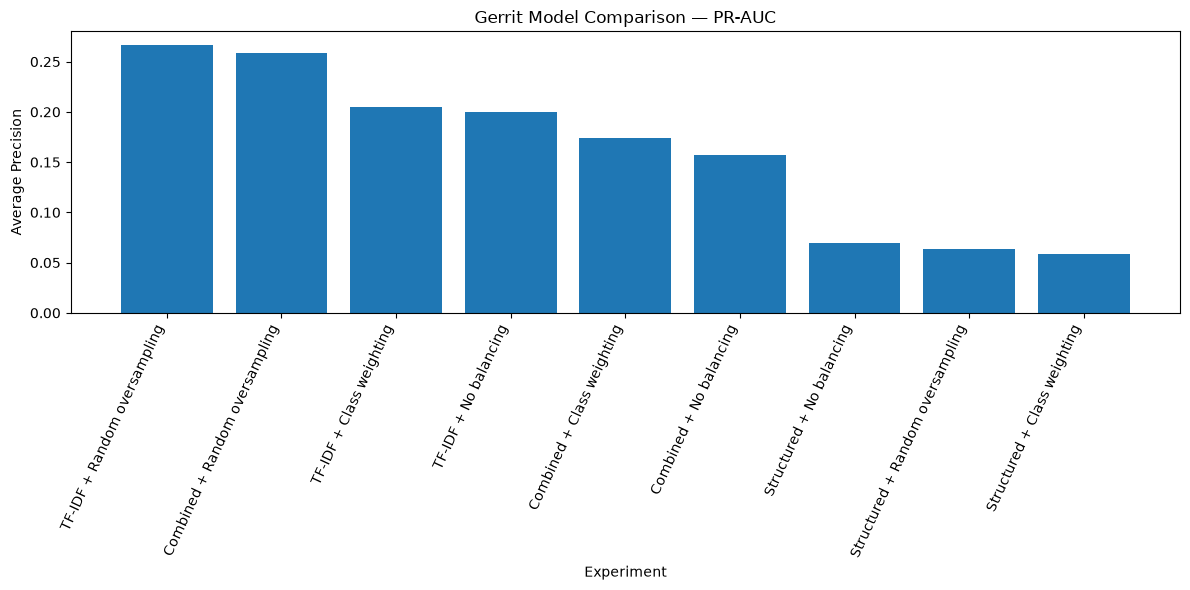

In [13]:
results_df["Experiment"] = (
    results_df["Feature Set"] +
    " + " +
    results_df["Imbalance Strategy"]
)

plt.figure(figsize=(12, 6))

plt.bar(
    results_df["Experiment"],
    results_df["PR_AUC"]
)

plt.title("Gerrit Model Comparison — PR-AUC")
plt.ylabel("Average Precision")
plt.xlabel("Experiment")
plt.xticks(rotation=65, ha="right")

plt.tight_layout()
plt.show()

Best experiment: ('TF-IDF', 'Random oversampling')

Classification Report:
                      precision    recall  f1-score   support

Not security-related       0.97      0.96      0.96       341
    Security-related       0.21      0.29      0.24        14

            accuracy                           0.93       355
           macro avg       0.59      0.62      0.60       355
        weighted avg       0.94      0.93      0.93       355



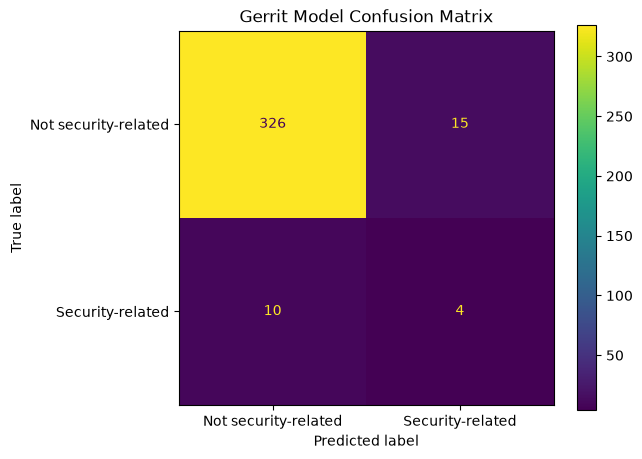

In [16]:
best_result = results_df.iloc[0]

best_key = (
    best_result["Feature Set"],
    best_result["Imbalance Strategy"]
)

best_model = trained_models[best_key]

X_best_test = feature_sets[best_key[0]][1]

best_predictions = best_model.predict(X_best_test)

best_probabilities = best_model.predict_proba(
    X_best_test
)[:, 1]

print("Best experiment:", best_key)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "Not security-related",
            "Security-related"
        ],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=[
        "Not security-related",
        "Security-related"
    ]
)

plt.title("Gerrit Model Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    balanced_accuracy_score
)

from imblearn.over_sampling import RandomOverSampler
from scipy.sparse import hstack, csr_matrix

import numpy as np
import pandas as pd

print("Cross-validation libraries imported successfully.")

Cross-validation libraries imported successfully.


In [18]:
STRUCTURED_FEATURES = [
    "diff_character_count",
    "diff_line_count",
    "added_line_count",
    "deleted_line_count",
    "changed_file_count_from_diff",
    "java_file_count",
    "test_file_count",
    "unique_file_extension_count",
    "java_file_indicator",
    "conditional_count",
    "loop_count",
    "exception_count",
    "method_declaration_count",
    "review_message_count",
    "review_message_character_count",
    "changed_files",
    "insertions",
    "deletions",
    "security_authentication_count",
    "security_authorization_count",
    "security_credentials_count",
    "security_cryptography_count",
    "security_input_validation_count",
    "added_security_indicator_count",
    "deleted_security_indicator_count"
]

SECURITY_INDICATORS = [
    "security_authentication_count",
    "security_authorization_count",
    "security_credentials_count",
    "security_cryptography_count",
    "security_input_validation_count",
    "added_security_indicator_count",
    "deleted_security_indicator_count"
]

# Use the complete modelling dataset prepared in Cell 4.
cv_df = model_df.copy()

cv_df = cv_df[
    cv_df["code_diff"].notna()
    & (cv_df["code_diff"].astype(str).str.strip() != "")
].copy()

cv_df["target"] = cv_df["target"].astype(int)

print("Cross-validation dataset:", cv_df.shape)
print("\nTarget distribution:")
print(cv_df["target"].value_counts())

print("\nUnique reviews:", cv_df["review_number"].nunique())

assert all(col in cv_df.columns for col in STRUCTURED_FEATURES)
assert "code_diff" in cv_df.columns
assert "review_number" in cv_df.columns

Cross-validation dataset: (1774, 36)

Target distribution:
target
0    1703
1      71
Name: count, dtype: int64

Unique reviews: 808


In [19]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X_text = cv_df["code_diff"].fillna("").astype(str).values
X_struct = cv_df[STRUCTURED_FEATURES].copy()

y = cv_df["target"].values
groups = cv_df["review_number"].values

experiments = [
    ("Structured", "No balancing"),
    ("Structured", "Class weighting"),
    ("Structured", "Random oversampling"),

    ("TF-IDF", "No balancing"),
    ("TF-IDF", "Class weighting"),
    ("TF-IDF", "Random oversampling"),

    ("Combined", "No balancing"),
    ("Combined", "Class weighting"),
    ("Combined", "Random oversampling")
]

cv_results = []

for fold_number, (train_idx, valid_idx) in enumerate(
    cv.split(X_text, y, groups),
    start=1
):

    print(f"\nProcessing fold {fold_number}...")

    X_text_train = X_text[train_idx]
    X_text_valid = X_text[valid_idx]

    X_struct_train = X_struct.iloc[train_idx]
    X_struct_valid = X_struct.iloc[valid_idx]

    y_train_fold = y[train_idx]
    y_valid_fold = y[valid_idx]

    train_groups = set(groups[train_idx])
    valid_groups = set(groups[valid_idx])

    assert train_groups.isdisjoint(valid_groups)

    print(
        "Training positives:",
        int(y_train_fold.sum()),
        "| Validation positives:",
        int(y_valid_fold.sum())
    )

    if len(np.unique(y_train_fold)) < 2:
        print("Skipping fold: training data contains only one class.")
        continue

    if len(np.unique(y_valid_fold)) < 2:
        print("Skipping fold: validation data contains only one class.")
        continue

    # Structured preprocessing: fit only on this fold's training data.
    imputer = SimpleImputer(strategy="median")

    struct_train = imputer.fit_transform(X_struct_train)
    struct_valid = imputer.transform(X_struct_valid)

    scaler = StandardScaler()

    struct_train = scaler.fit_transform(struct_train)
    struct_valid = scaler.transform(struct_valid)

    struct_train = csr_matrix(struct_train)
    struct_valid = csr_matrix(struct_valid)

    # TF-IDF preprocessing: fit only on this fold's training data.
    vectorizer = TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        dtype=np.float32
    )

    text_train = vectorizer.fit_transform(X_text_train)
    text_valid = vectorizer.transform(X_text_valid)

    feature_matrices = {
        "Structured": (struct_train, struct_valid),
        "TF-IDF": (text_train, text_valid),
        "Combined": (
            hstack([struct_train, text_train]).tocsr(),
            hstack([struct_valid, text_valid]).tocsr()
        )
    }

    for feature_name, strategy in experiments:

        X_train_fold, X_valid_fold = feature_matrices[feature_name]

        class_weight = (
            "balanced"
            if strategy == "Class weighting"
            else None
        )

        model = LogisticRegression(
            max_iter=2000,
            class_weight=class_weight,
            random_state=42
        )

        X_fit = X_train_fold
        y_fit = y_train_fold

        if strategy == "Random oversampling":
            sampler = RandomOverSampler(random_state=42)

            X_fit, y_fit = sampler.fit_resample(
                X_train_fold,
                y_train_fold
            )

        model.fit(X_fit, y_fit)

        predictions = model.predict(X_valid_fold)
        probabilities = model.predict_proba(X_valid_fold)[:, 1]

        cv_results.append({
            "Fold": fold_number,
            "Feature Set": feature_name,
            "Imbalance Strategy": strategy,
            "Training Rows": len(y_fit),
            "Validation Rows": len(y_valid_fold),
            "Validation Positives": int(y_valid_fold.sum()),
            "Precision": precision_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "PR_AUC": average_precision_score(
                y_valid_fold, probabilities
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_valid_fold, predictions
            )
        })

cv_results_df = pd.DataFrame(cv_results)

print("\nCross-validation completed.")
display(cv_results_df)


Processing fold 1...
Training positives: 57 | Validation positives: 14

Processing fold 2...
Training positives: 57 | Validation positives: 14

Processing fold 3...
Training positives: 58 | Validation positives: 13

Processing fold 4...
Training positives: 55 | Validation positives: 16

Processing fold 5...
Training positives: 57 | Validation positives: 14

Cross-validation completed.


,Fold,Feature Set,Imbalance Strategy,Training Rows,Validation Rows,Validation Positives,Precision,Recall,F1,PR_AUC,Balanced Accuracy
0,1,Structured,No balancing,1419,355,14,0.000000,0.000000,0.000000,0.069779,0.500000
1,1,Structured,Class weighting,1419,355,14,0.044444,0.428571,0.080537,0.058385,0.525136
2,1,Structured,Random oversampling,2724,355,14,0.044118,0.428571,0.080000,0.063831,0.523670
3,1,TF-IDF,No balancing,1419,355,14,0.000000,0.000000,0.000000,0.200065,0.500000
4,1,TF-IDF,Class weighting,1419,355,14,0.181818,0.285714,0.222222,0.204750,0.616464
5,1,TF-IDF,Random oversampling,2724,355,14,0.210526,0.285714,0.242424,0.266835,0.620863
6,1,Combined,No balancing,1419,355,14,0.000000,0.000000,0.000000,0.157032,0.500000
7,1,Combined,Class weighting,1419,355,14,0.222222,0.285714,0.250000,0.174376,0.622329
8,1,Combined,Random oversampling,2724,355,14,0.222222,0.285714,0.250000,0.258842,0.622329
9,2,Structured,No balancing,1419,355,14,0.000000,0.000000,0.000000,0.059603,0.500000


In [20]:
cv_summary = (
    cv_results_df
    .groupby(["Feature Set", "Imbalance Strategy"])
    .agg(
        Mean_Precision=("Precision", "mean"),
        Std_Precision=("Precision", "std"),
        Mean_Recall=("Recall", "mean"),
        Std_Recall=("Recall", "std"),
        Mean_F1=("F1", "mean"),
        Std_F1=("F1", "std"),
        Mean_PR_AUC=("PR_AUC", "mean"),
        Std_PR_AUC=("PR_AUC", "std"),
        Mean_Balanced_Accuracy=("Balanced Accuracy", "mean")
    )
    .reset_index()
    .sort_values("Mean_PR_AUC", ascending=False)
)

display(cv_summary.round(4))

print("\nBest grouped cross-validation experiment:")
display(cv_summary.head(1).round(4))

,Feature Set,Imbalance Strategy,Mean_Precision,Std_Precision,Mean_Recall,Std_Recall,Mean_F1,Std_F1,Mean_PR_AUC,Std_PR_AUC,Mean_Balanced_Accuracy
8,TF-IDF,Random oversampling,0.3006,0.0780,0.3723,0.1443,0.3240,0.0785,0.3292,0.1502,0.6673
2,Combined,Random oversampling,0.2835,0.0560,0.3609,0.1307,0.3036,0.0431,0.3080,0.0934,0.6599
6,TF-IDF,Class weighting,0.2911,0.0964,0.3876,0.1397,0.3187,0.0679,0.2929,0.1394,0.6721
0,Combined,Class weighting,0.2635,0.0633,0.3609,0.1307,0.2886,0.0342,0.2775,0.1054,0.6572
7,TF-IDF,No balancing,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2460,0.0769,0.5000
1,Combined,No balancing,0.3500,0.4873,0.0529,0.0823,0.0886,0.1334,0.2455,0.0909,0.5261
3,Structured,Class weighting,0.0581,0.0128,0.6782,0.1831,0.1069,0.0240,0.1256,0.0869,0.6119
5,Structured,Random oversampling,0.0589,0.0115,0.6924,0.1753,0.1084,0.0216,0.1242,0.0833,0.6178
4,Structured,No balancing,0.3333,0.4714,0.0404,0.0579,0.0707,0.0997,0.1239,0.0805,0.5199



Best grouped cross-validation experiment:


,Feature Set,Imbalance Strategy,Mean_Precision,Std_Precision,Mean_Recall,Std_Recall,Mean_F1,Std_F1,Mean_PR_AUC,Std_PR_AUC,Mean_Balanced_Accuracy
8,TF-IDF,Random oversampling,0.3006,0.078,0.3723,0.1443,0.324,0.0785,0.3292,0.1502,0.6673


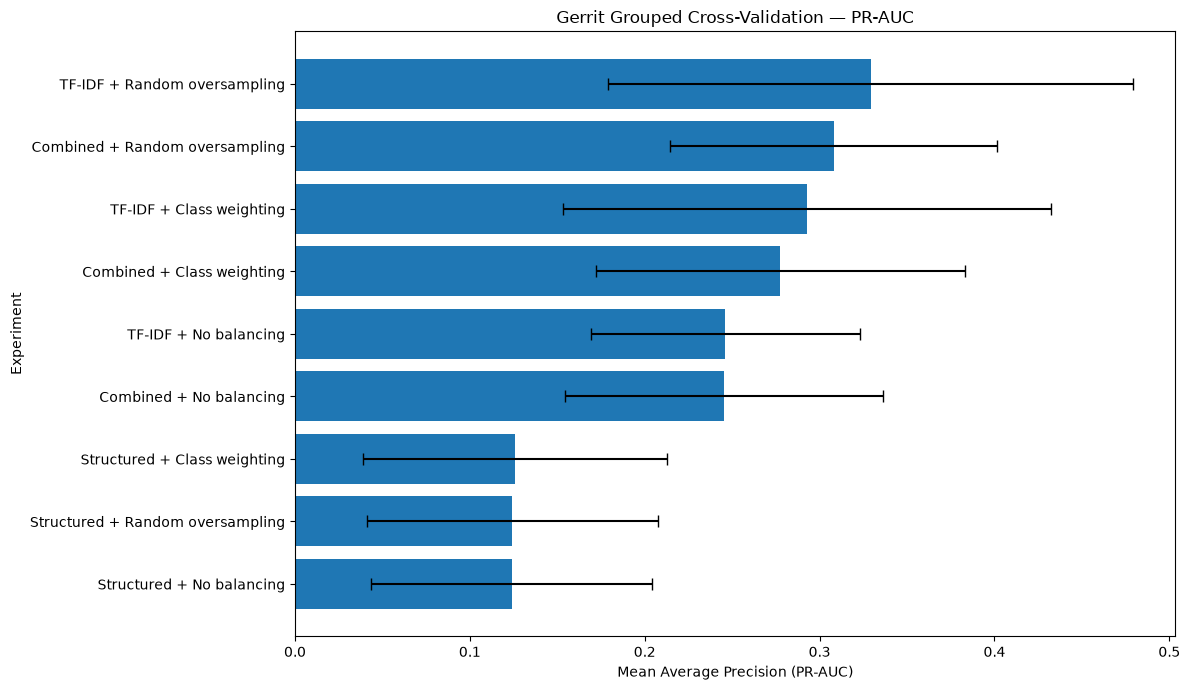

In [21]:
import matplotlib.pyplot as plt

plot_df = cv_summary.sort_values(
    "Mean_PR_AUC",
    ascending=True
)

labels = (
    plot_df["Feature Set"]
    + " + "
    + plot_df["Imbalance Strategy"]
)

plt.figure(figsize=(12, 7))

plt.barh(
    labels,
    plot_df["Mean_PR_AUC"],
    xerr=plot_df["Std_PR_AUC"],
    capsize=4
)

plt.xlabel("Mean Average Precision (PR-AUC)")
plt.ylabel("Experiment")
plt.title("Gerrit Grouped Cross-Validation — PR-AUC")
plt.tight_layout()
plt.show()

In [22]:
ABLATION_FEATURES = [
    col for col in STRUCTURED_FEATURES
    if col not in SECURITY_INDICATORS
]

print("Original structured feature count:", len(STRUCTURED_FEATURES))
print("After removing security indicators:", len(ABLATION_FEATURES))

print("\nRemoved features:")
print(SECURITY_INDICATORS)

Original structured feature count: 25
After removing security indicators: 18

Removed features:
['security_authentication_count', 'security_authorization_count', 'security_credentials_count', 'security_cryptography_count', 'security_input_validation_count', 'added_security_indicator_count', 'deleted_security_indicator_count']


In [23]:
ablation_results = []

for fold_number, (train_idx, valid_idx) in enumerate(
    cv.split(X_text, y, groups),
    start=1
):

    print(f"Processing ablation fold {fold_number}...")

    X_text_train = X_text[train_idx]
    X_text_valid = X_text[valid_idx]

    y_train_fold = y[train_idx]
    y_valid_fold = y[valid_idx]

    # Original structured features.
    original_train = X_struct.iloc[train_idx]
    original_valid = X_struct.iloc[valid_idx]

    # Structured features without security indicators.
    reduced_train = original_train[ABLATION_FEATURES]
    reduced_valid = original_valid[ABLATION_FEATURES]

    def prepare_structured(train_data, valid_data):
        imputer = SimpleImputer(strategy="median")

        train_data = imputer.fit_transform(train_data)
        valid_data = imputer.transform(valid_data)

        scaler = StandardScaler()

        train_data = scaler.fit_transform(train_data)
        valid_data = scaler.transform(valid_data)

        return csr_matrix(train_data), csr_matrix(valid_data)

    original_train_matrix, original_valid_matrix = prepare_structured(
        original_train, original_valid
    )

    reduced_train_matrix, reduced_valid_matrix = prepare_structured(
        reduced_train, reduced_valid
    )

    # Fit TF-IDF separately within this fold.
    vectorizer = TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        dtype=np.float32
    )

    text_train = vectorizer.fit_transform(X_text_train)
    text_valid = vectorizer.transform(X_text_valid)

    feature_sets = {
        "Combined - All Structured Features": (
            hstack([original_train_matrix, text_train]).tocsr(),
            hstack([original_valid_matrix, text_valid]).tocsr()
        ),
        "Combined - Without Security Indicators": (
            hstack([reduced_train_matrix, text_train]).tocsr(),
            hstack([reduced_valid_matrix, text_valid]).tocsr()
        )
    }

    for feature_name, (X_train_fold, X_valid_fold) in feature_sets.items():

        for strategy in [
            "No balancing",
            "Class weighting",
            "Random oversampling"
        ]:

            class_weight = (
                "balanced"
                if strategy == "Class weighting"
                else None
            )

            model = LogisticRegression(
                max_iter=2000,
                class_weight=class_weight,
                random_state=42
            )

            X_fit = X_train_fold
            y_fit = y_train_fold

            if strategy == "Random oversampling":
                sampler = RandomOverSampler(random_state=42)

                X_fit, y_fit = sampler.fit_resample(
                    X_train_fold,
                    y_train_fold
                )

            model.fit(X_fit, y_fit)

            predictions = model.predict(X_valid_fold)
            probabilities = model.predict_proba(X_valid_fold)[:, 1]

            ablation_results.append({
                "Fold": fold_number,
                "Feature Set": feature_name,
                "Imbalance Strategy": strategy,
                "Precision": precision_score(
                    y_valid_fold, predictions, zero_division=0
                ),
                "Recall": recall_score(
                    y_valid_fold, predictions, zero_division=0
                ),
                "F1": f1_score(
                    y_valid_fold, predictions, zero_division=0
                ),
                "PR_AUC": average_precision_score(
                    y_valid_fold, probabilities
                ),
                "Balanced Accuracy": balanced_accuracy_score(
                    y_valid_fold, predictions
                )
            })

ablation_df = pd.DataFrame(ablation_results)

print("Ablation experiment completed.")
display(ablation_df)

Processing ablation fold 1...
Processing ablation fold 2...
Processing ablation fold 3...
Processing ablation fold 4...
Processing ablation fold 5...
Ablation experiment completed.


,Fold,Feature Set,Imbalance Strategy,Precision,Recall,F1,PR_AUC,Balanced Accuracy
0,1,Combined - All Structured Features,No balancing,0.000000,0.000000,0.000000,0.157032,0.500000
1,1,Combined - All Structured Features,Class weighting,0.222222,0.285714,0.250000,0.174376,0.622329
2,1,Combined - All Structured Features,Random oversampling,0.222222,0.285714,0.250000,0.258842,0.622329
3,1,Combined - Without Security Indicators,No balancing,0.000000,0.000000,0.000000,0.197028,0.500000
4,1,Combined - Without Security Indicators,Class weighting,0.238095,0.357143,0.285714,0.207245,0.655111
5,1,Combined - Without Security Indicators,Random oversampling,0.250000,0.357143,0.294118,0.266337,0.656577
6,2,Combined - All Structured Features,No balancing,0.000000,0.000000,0.000000,0.151717,0.500000
7,2,Combined - All Structured Features,Class weighting,0.375000,0.214286,0.272727,0.204813,0.599811
8,2,Combined - All Structured Features,Random oversampling,0.375000,0.214286,0.272727,0.228915,0.599811
9,2,Combined - Without Security Indicators,No balancing,0.000000,0.000000,0.000000,0.194907,0.500000


In [24]:
ablation_summary = (
    ablation_df
    .groupby(["Feature Set", "Imbalance Strategy"])
    .agg(
        Mean_Precision=("Precision", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_F1=("F1", "mean"),
        Mean_PR_AUC=("PR_AUC", "mean"),
        Std_PR_AUC=("PR_AUC", "std"),
        Mean_Balanced_Accuracy=("Balanced Accuracy", "mean")
    )
    .reset_index()
    .sort_values("Mean_PR_AUC", ascending=False)
)

display(ablation_summary.round(4))

,Feature Set,Imbalance Strategy,Mean_Precision,Mean_Recall,Mean_F1,Mean_PR_AUC,Std_PR_AUC,Mean_Balanced_Accuracy
5,Combined - Without Security Indicators,Random oversampling,0.2957,0.3758,0.3236,0.3217,0.1195,0.6682
2,Combined - All Structured Features,Random oversampling,0.2835,0.3609,0.3036,0.3080,0.0934,0.6599
3,Combined - Without Security Indicators,Class weighting,0.2864,0.3901,0.3212,0.3021,0.1318,0.6733
0,Combined - All Structured Features,Class weighting,0.2635,0.3609,0.2886,0.2775,0.1054,0.6572
1,Combined - All Structured Features,No balancing,0.3500,0.0529,0.0886,0.2455,0.0909,0.5261
4,Combined - Without Security Indicators,No balancing,0.0000,0.0000,0.0000,0.2395,0.0839,0.5000


In [ ]:
OUTPUT_DIR = Path(
    "../data/gerrit/couchbase_java_client/modeling_results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

results_df.to_csv(
    OUTPUT_DIR / "gerrit_imbalance_experiment_results.csv",
    index=False
)

predictions_df = test_df[
    ["review_number", "revision_number", "security_label"]
].copy()

predictions_df["actual_target"] = y_test
predictions_df["predicted_target"] = best_predictions
predictions_df["predicted_probability"] = best_probabilities

predictions_df.to_csv(
    OUTPUT_DIR / "gerrit_test_predictions.csv",
    index=False
)

print("Results saved successfully.")